# Bài tập Thực hành: Phân loại Âm thanh - Speech Commands Dataset (MFCCs + SVM)

Trong bài tập này, các bạn sẽ thực hành xây dựng và đánh giá quy trình Phân loại Lệnh Giọng nói (Speech Commands) sử dụng phương pháp Học máy truyền thống. Quy trình bao gồm các bước cốt lõi:

1. **Tải & Lọc Dữ liệu Âm thanh**: Tải tự động bộ dữ liệu `Speech Commands Dataset` bằng `torchaudio.datasets` và lọc ra tập con gồm 10 từ khóa cơ bản để tối ưu thời gian huấn luyện.
2. **Tiền xử lý Độ dài Tín hiệu (Padding/Truncating)**: Do các file âm thanh có độ dài không đồng đều, bạn sẽ sử dụng `torch.nn.functional.pad` để chuẩn hóa tất cả các mảng `waveform` về đúng kích thước cố định `(1, 16000)` (tương đương 1 giây).
3. **Trích xuất Đặc trưng MFCCs**: Khởi tạo biến đổi `torchaudio.transforms.MFCC` để trích xuất đặc trưng Cepstral từ tín hiệu âm thanh.
4. **Chuyển đổi Không gian Chiều (Mean Pooling)**: Xử lý tensor MFCCs 2D đầu ra thành vector đặc trưng 1D bằng cách tính trung bình dọc theo trục thời gian (`dim=-1`), nhằm đáp ứng yêu cầu đầu vào của mô hình SVM.
5. **Huấn luyện Mô hình SVM**: Sử dụng thư viện `sklearn.svm.SVC` để huấn luyện mô hình phân loại đa lớp trên tập đặc trưng MFCCs 1D.
6. **Đánh giá & Trực quan hóa**: Sử dụng `sklearn.metrics` để tính toán và hiển thị **Classification Report**, đồng thời vẽ ma trận nhầm lẫn để phân tích độ chính xác của mô hình.
7. **Câu hỏi thảo luận**: Phân tích tầm quan trọng của việc chuẩn hóa độ dài tín hiệu và cơ chế giải tương quan của biến đổi DCT trong thuật toán MFCCs.

### 1. Import các thư viện cần thiết

In [1]:
import os
import torch
import torchaudio
import torchaudio.transforms as T
import librosa
import numpy as np
from torch.nn.functional import pad
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
np.random.seed(42)

### 2. Tải và Lọc bộ dữ liệu Speech Commands
Bộ dữ liệu Speech Commands chứa 35 từ khác nhau. Để mô hình SVM huấn luyện nhanh và hiệu quả trong khuôn khổ bài thực hành, chúng ta sẽ lọc ra **10 từ khóa cơ bản** (ví dụ: *yes, no, up, down, left, right, on, off, stop, go*).

In [2]:
# TODO 1.1: Tải dataset bằng torchaudio.datasets.SPEECHCOMMANDS
TARGET_WORDS = ['yes', 'no', 'up', 'down', 'left', 'right', 'on', 'off', 'stop', 'go']
word_to_idx = {word: i for i, word in enumerate(TARGET_WORDS)}

data_root = 'speech_commands_data'
os.makedirs(data_root, exist_ok=True)
print("Đang tải Speech Commands Dataset...")
train_dataset = torchaudio.datasets.SPEECHCOMMANDS(
    data_root, download=True, subset='training'
)
test_dataset = torchaudio.datasets.SPEECHCOMMANDS(
    data_root, download=True, subset='testing'
)

def filter_dataset(dataset, max_per_class):
    filtered_data = []
    counts = {word: 0 for word in TARGET_WORDS}

    for index, wav_path in enumerate(dataset._walker):
        label = os.path.basename(os.path.dirname(wav_path))
        if label in TARGET_WORDS and counts[label] < max_per_class:
            audio, sample_rate = librosa.load(wav_path, sr=16000, mono=True)
            waveform = torch.tensor(audio, dtype=torch.float32).unsqueeze(0)
            filtered_data.append((waveform, sample_rate, word_to_idx[label]))
            counts[label] += 1

        if all(counts[word] == max_per_class for word in TARGET_WORDS):
            break

    return filtered_data

# TODO 1.2: Lọc 400 mẫu train và 100 mẫu test cho mỗi lớp
train_data = filter_dataset(train_dataset, max_per_class=400)
test_data = filter_dataset(test_dataset, max_per_class=100)

print(f"Số mẫu Train: {len(train_data)}")
print(f"Số mẫu Test: {len(test_data)}")

Đang tải Speech Commands Dataset...


D:\DuyToan\Python\DUT_AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Số mẫu Train: 4000
Số mẫu Test: 1000


### 3. Khởi tạo bộ trích xuất MFCCs

In [3]:
# TODO 2: Khởi tạo torchaudio.transforms.MFCC
sample_rate = 16000
mfcc_transform = T.MFCC(
    sample_rate=sample_rate,
    n_mfcc=13,
    melkwargs={
        'n_fft': 400,
        'hop_length': 160,
        'n_mels': 40
    }
)

print(mfcc_transform)

MFCC(
  (amplitude_to_DB): AmplitudeToDB()
  (MelSpectrogram): MelSpectrogram(
    (spectrogram): Spectrogram()
    (mel_scale): MelScale()
  )
)


### 4. Tiền xử lý (Padding/Truncating) và Trích xuất Đặc trưng
**Vấn đề:** Các file âm thanh trong Speech Commands có độ dài tối đa là 1 giây (16000 samples), nhưng có nhiều file bị cắt ngắn hơn (ví dụ: 14000, 15000 samples).

**Giải pháp:** Cần chuẩn hóa mảng `waveform` về đúng kích thước cố định `(1, 16000)` trước khi đưa qua hàm tính MFCC. Sau đó áp dụng `.mean(dim=-1)` để chuyển tensor 2D thành vector 1D.

In [4]:
# TODO 3: Tiền xử lý và trích xuất MFCC
def preprocess_and_extract_mfcc(dataset, transform, max_length=16000):
    X = []
    y = []

    for waveform, sr, label in dataset:
        # TODO 3.1: Padding hoặc Truncating waveform về đúng 16000 samples
        if waveform.shape[1] < max_length:
            waveform = pad(waveform, (0, max_length - waveform.shape[1]))
        else:
            waveform = waveform[:, :max_length]

        # TODO 3.2: Trích xuất MFCC và lấy trung bình theo trục thời gian
        mfcc = transform(waveform)
        feature_vector = mfcc.mean(dim=-1).squeeze(0)

        # TODO 3.3: Thêm vector đặc trưng và nhãn vào mảng kết quả
        X.append(feature_vector.numpy())
        y.append(label)

    return np.array(X), np.array(y)

X_train, y_train = preprocess_and_extract_mfcc(train_data, mfcc_transform)
X_test, y_test = preprocess_and_extract_mfcc(test_data, mfcc_transform)

print(f"Kích thước X_train: {X_train.shape}")
print(f"Kích thước X_test: {X_test.shape}")

Kích thước X_train: (4000, 13)
Kích thước X_test: (1000, 13)


### 5. Huấn luyện SVM

In [5]:
# TODO 4: Khởi tạo và huấn luyện mô hình SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_model = SVC(kernel='rbf', C=10, gamma='scale')
svm_model.fit(X_train_scaled, y_train)

print("Đã huấn luyện xong mô hình SVM.")

Đã huấn luyện xong mô hình SVM.


### 6. Đánh giá Mô hình

Test Accuracy: 0.3520

Classification Report:
              precision    recall  f1-score   support

         yes       0.50      0.58      0.54       100
          no       0.22      0.25      0.24       100
          up       0.37      0.36      0.36       100
        down       0.31      0.28      0.30       100
        left       0.28      0.27      0.28       100
       right       0.36      0.51      0.42       100
          on       0.34      0.33      0.34       100
         off       0.35      0.34      0.35       100
        stop       0.36      0.24      0.29       100
          go       0.40      0.36      0.38       100

    accuracy                           0.35      1000
   macro avg       0.35      0.35      0.35      1000
weighted avg       0.35      0.35      0.35      1000



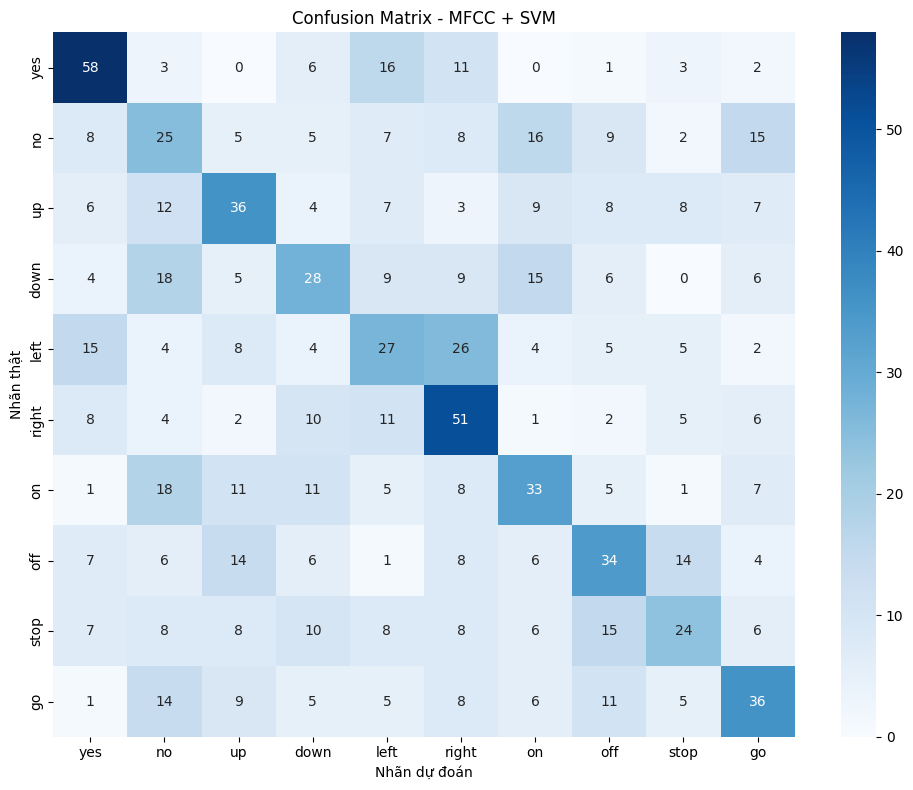

In [6]:
# TODO 5: Đánh giá độ chính xác trên tập Test
y_pred = svm_model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=range(len(TARGET_WORDS)),
    target_names=TARGET_WORDS,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=range(len(TARGET_WORDS)))
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=TARGET_WORDS, yticklabels=TARGET_WORDS)
plt.title('Confusion Matrix - MFCC + SVM')
plt.xlabel('Nhãn dự đoán')
plt.ylabel('Nhãn thật')
plt.tight_layout()
plt.show()

### 7. Thảo luận

**Câu hỏi 1:** Tại sao phải Padding/Truncating trước khi trích xuất đặc trưng? Nếu bỏ qua thì đầu vào SVM sẽ ra sao?

**Trả lời:** Mỗi file có số mẫu khác nhau nên số frame MFCC cũng khác nhau. Padding hoặc cắt về cùng 16.000 mẫu giúp mọi ma trận MFCC có cùng số cột thời gian. Sau phép lấy trung bình, mỗi file đều trở thành một vector 13 phần tử. Nếu bỏ qua bước chuẩn hóa và dùng trực tiếp ma trận theo thời gian, các vector có thể khác kích thước nên không thể ghép thành một ma trận đầu vào cố định cho SVM. Trong bài này mean pooling cuối cùng vẫn tạo vector 13 chiều, nhưng chuẩn hóa độ dài giúp mỗi vector đại diện cho cùng một khoảng thời gian và dễ so sánh công bằng hơn.

**Câu hỏi 2:** Vì sao MFCC phù hợp với SVM/GMM hơn Log-Mel Spectrogram khi xét phép biến đổi DCT?

**Trả lời:** Các dải tần Log-Mel lân cận thường tương quan với nhau. DCT biến đổi chúng thành các hệ số cepstral ít tương quan hơn và dồn phần lớn thông tin về bao phổ vào một số hệ số đầu. Vì vậy MFCC có số chiều nhỏ, ít dư thừa và dễ đưa vào SVM hoặc GMM. Log-Mel giữ cấu trúc hai chiều chi tiết hơn nên rất phù hợp với CNN, nhưng nếu đưa thẳng vào mô hình truyền thống thì thường phải làm phẳng thành vector lớn và còn nhiều đặc trưng tương quan.